##### *Reincidencia de sentenciados en prisiones del Perú*
# **Modelos implementados**
## **Integrantes**
* Renzo Dacillo
* Pierre Lavergne
* Luis Alberto Carrasco


In [154]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE

In [155]:
Dataset = pd.read_csv('sample_data/Dataset_procesado.csv')

In [156]:
print(Dataset.columns)

Index(['ID_CARATULA', 'DI', 'EST_PENIT', 'GENERO', 'E_CIVIL', 'RELIGION',
       'EDAD', 'NACIONALIDAD', 'INT_DD', 'DELITO_GENERICO', 'P101', 'P103_1',
       'P103_2', 'P103_3', 'P104_1', 'P104_4_CCEE', 'P105', 'P107_8', 'P107_9',
       'P107_10', 'P109A_2', 'P114', 'P117', 'P122', 'P124', 'P126', 'P127',
       'P128', 'P129', 'P135', 'P136', 'P137', 'P203', 'P215', 'P315', 'P303',
       'REINCIDENTE'],
      dtype='object')


In [157]:
#One-Hot Encoding
df = pd.get_dummies(Dataset, drop_first=True,dtype=int)
print(df.shape)

(38624, 330)


In [158]:
#Imputación simple
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')

df_imputado = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

In [159]:
# Código copiado del notebook del Laboratorio 3 del curso
# Completar: separar features y target
X =df_imputado.drop(['ID_CARATULA','REINCIDENTE'], axis=1)
y =df_imputado['REINCIDENTE']

In [160]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=3)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Prevalencia train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Train: (30899, 328) | Test: (7725, 328)
Prevalencia train/test: 0.165 0.165


In [161]:
#SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(pd.Series(y_train_smote).value_counts())

REINCIDENTE
0.0    25809
1.0    25809
Name: count, dtype: int64


In [162]:
# NO MODIFICAR
print(f"Datos de entrenamiento: {X_train_smote.shape[0]} lanzamientos")
print(f"Datos de prueba: {X_test.shape[0]} lanzamientos")

pd.DataFrame({
    'Conjunto': ['Entrenamiento', 'Prueba', 'Total'],
    'Muestras': [len(X_train), len(X_test), len(X)],
    'Features': [X_train_smote.shape[1], X_test.shape[1], X.shape[1]],
    'Proporción de Reincidentes': [y_train_smote.mean(), y_test.mean(), y.mean()]
})


Datos de entrenamiento: 51618 lanzamientos
Datos de prueba: 7725 lanzamientos


,Conjunto,Muestras,Features,Proporción de Reincidentes
0,Entrenamiento,30899,328,0.500000
1,Prueba,7725,328,0.164790
2,Total,38624,328,0.164742


In [163]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),

    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

In [164]:
# Completar: entrenar
pipeline.fit(X_train_smote, y_train_smote)

# Completar: realizar predicciones
y_pred =pipeline.predict(X_test)


# Completar: calcular accuracy
accuracy_final =accuracy_score(y_test,y_pred)

In [165]:
print(f"Accuracy en test = {accuracy_final:.4f}")
print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['No reincidente', 'Reincidente']
))


Accuracy en test = 0.6612

Reporte de clasificación:
                precision    recall  f1-score   support

No reincidente       0.91      0.66      0.77      6452
   Reincidente       0.28      0.65      0.39      1273

      accuracy                           0.66      7725
     macro avg       0.59      0.66      0.58      7725
  weighted avg       0.80      0.66      0.70      7725



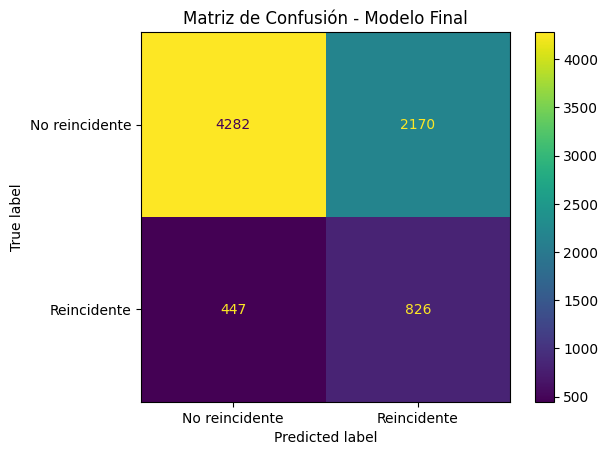

In [166]:
# Completar: calcular matriz de confusión
matriz =confusion_matrix(y_test, y_pred)

# NO MODIFICAR
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['No reincidente', 'Reincidente']
)
disp.plot()
plt.title('Matriz de Confusión - Modelo Final')
plt.show()

No predice bien los reincidentes, posiblemente porque no se realizaron imputaciones más adecuadas o una técnica de balanceo distinto. El modelo de IA también influye.